# Full-model prediction contrasts

A fitted component answers how one learner contributes on the link scale. A prediction
contrast answers a different question: how the complete model prediction changes when
one variable is set to two reference values while every other predictor retains each
row's observed value. `prediction_contrast` averages those row changes over a named
population and retains each contribution.

The result is an adjusted prediction contrast. It becomes a causal effect only when the
two settings define an intervention and the adjustment, timing, positivity, consistency,
and interference assumptions identify that intervention. The
[causal workflow](causal.ipynb) records those additional claims.


## Response-scale contrasts: `prediction_contrast`

A nonidentity link transforms the complete additive predictor. The same link-scale change
therefore gives different probability changes for rows with different baseline risk. A
response contrast must predict the complete model under both settings and subtract those
probabilities; transforming an isolated learner contribution does not compute that
quantity.


In [1]:
import numpy as np
import polars as pl
import mboostrs as mb

rng = np.random.default_rng(8)
n = 500
x = rng.uniform(-1, 1, n)
baseline = rng.normal(size=n)
probability = 1 / (1 + np.exp(-(0.7 * x + 1.2 * baseline)))
event = rng.binomial(1, probability)
data = pl.DataFrame({"x": x, "baseline": baseline, "event": event})
fit = mb.glmboost(
    "event ~ x + baseline", data, family=mb.Binomial(),
    control=mb.boost_control(150, 0.1),
)
response_change = mb.prediction_contrast(
    fit, data, "x", -0.5, 0.5, type="response",
    population="simulated study rows",
)
link_change = mb.prediction_contrast(
    fit, data, "x", -0.5, 0.5, type="link",
    population="simulated study rows",
)
pl.DataFrame({
    "scale": ["probability", "link"],
    "average contrast": [response_change.estimate, link_change.estimate],
    "row-to-row standard deviation": [
        response_change.individual.std(), link_change.individual.std(),
    ],
})


scale,average contrast,row-to-row standard deviation
str,f64,f64
"""probability""",0.091706,0.027868
"""link""",0.239663,7.4507e-17


## Result structure: `ContrastResult`

`ContrastResult.estimate` is one scalar. `individual`, `reference_prediction`,
`alternative_prediction`, `weights`, and `observation_ids` each have one entry per
standardization row. `to_frame()` returns those arrays as a Polars table by default.
The weighted mean of `contrast` reconstructs `estimate`. Weights define the averaging
population; they do not add causal identification or sampling uncertainty.


In [2]:
contrast_rows = response_change.to_frame(output="polars")
reconstructed = np.average(contrast_rows["contrast"],
                           weights=contrast_rows["weight"])
assert np.isclose(reconstructed, response_change.estimate)
contrast_rows.head()


record_id,weight,reference_prediction,alternative_prediction,contrast
i64,f64,f64,f64,f64
0,1.0,0.573236,0.68447,0.111234
1,1.0,0.168826,0.247005,0.07818
2,1.0,0.768766,0.842995,0.074229
3,1.0,0.264068,0.366885,0.102817
4,1.0,0.595075,0.703561,0.108486


## Average marginal effects: `average_marginal_effect`

`average_marginal_effect` changes each row's observed value by a small recorded step.
Interior rows use a central difference; rows near a training boundary use the available
one-sided interval and divide by its actual width. The result retains both evaluation
points and predictions, so every derivative and their weighted average can be rebuilt.
For a Binomial response, the response-scale derivative varies with baseline risk even
when the link-scale derivative is constant. `plot_prediction_contrast` shows the
distribution of row contrasts; `plot_marginal_effect` shows local derivatives against
the predictor. Their reference rules mark weighted averages, not confidence limits.

`average_elasticity` evaluates a dimensionless elasticity
`d log(prediction) / d log(x)` or a semi-elasticity `d log(prediction) / dx`.
Elasticity requires positive predictors and both forms require positive response
predictions; the function refuses rather than take a logarithm whose
statistical meaning is undefined.


record_id,weight,lower_value,upper_value,lower_prediction,upper_prediction,marginal_effect
i64,f64,f64,f64,f64,f64,f64
0,1.0,-0.351055,-0.341055,0.590603,0.591762,0.115846
1,1.0,0.969554,0.979554,0.291197,0.292187,0.099032
2,1.0,-0.367578,-0.357578,0.779857,0.780678,0.08218
3,1.0,0.572098,0.582098,0.374948,0.376072,0.112403
4,1.0,0.734793,0.744793,0.726483,0.727435,0.095141


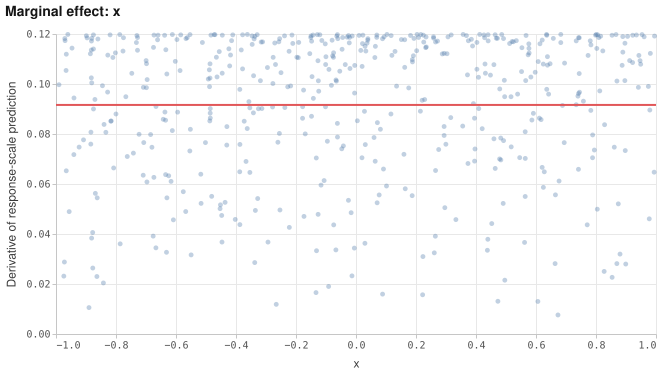

In [3]:
response_derivative = mb.average_marginal_effect(
    fit, data, "x", step=0.01, type="response",
    population="simulated study rows",
)
derivative_rows = response_derivative.to_frame(output="polars")
assert np.isclose(
    np.average(derivative_rows["marginal_effect"],
               weights=derivative_rows["weight"]),
    response_derivative.estimate,
)
display(derivative_rows.head())
mb.plot.plot_marginal_effect(response_derivative)


## Reference values and extrapolation

The default `extrapolation="error"` rejects any reference value outside the observed
training range, including a linear term. A linear formula can produce a number beyond
that range, but the data do not check that its slope continues there. `"warn"` records
that assumption while computing it, `"allow"` computes it silently, and `"clip"`
replaces the request with the nearest boundary and records both requested and effective
values in `result.support`. Unseen categorical levels are refused because clipping has no
meaning for unordered labels.

For distributional models, `parameter=` selects the location, scale, or shape predictor
for a parameter-specific contrast. `distributional_contrast` instead predicts every
parameter before evaluating a response mean, quantile, or strict exceedance probability.
A quantile can therefore move through location, scale, or shape even when one parameter's
isolated contrast is zero. `quantity="exceedance_probability"` uses
`P(Y > value) = 1-F(value)`, including count and mixed distributions.


## Partial dependence and ICE curves: `prediction_profile`

`prediction_profile` replaces the variable at a weighted quantile grid for every row.
The weighted average is partial dependence; retained row predictions are individual
conditional-expectation curves. The result reports the fraction of replacements more
than a chosen number of residual standard deviations from a weighted linear regression
of the variable on other numeric predictors. This diagnostic detects linear dependence;
nonlinear and categorical support restrictions can remain.

The diagnostic uses every other finite numeric column supplied to the function, even one absent from the fitted model. Supply the model predictors needed for the standardization population; an unused indicator derived from the replaced variable would remain fixed and could falsely suggest lack of support. The response is excluded automatically.


grid,average_prediction,support_fraction_far
f64,f64,f64
-0.992592,0.375407,0.0
-0.862126,0.38685,0.0
-0.68544,0.402524,0.0
-0.550461,0.414619,0.0
-0.397172,0.428465,0.0
…,…,…
0.40895,0.502466,0.0
0.528065,0.513462,0.0
0.647731,0.524497,0.0


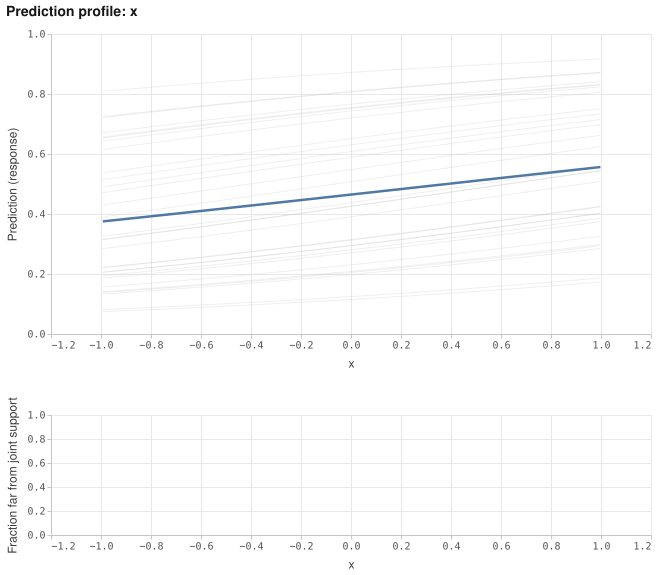

In [4]:
profile = mb.prediction_profile(fit, data, "x", points=15, type="response")
display(profile.to_frame(output="polars"))
mb.plot.plot_prediction_profile(profile, max_ice=30)


## Accumulated local effects: `accumulated_local_effect`

Partial dependence replaces a predictor globally and can pair it with other predictors
in combinations absent from correlated data. `accumulated_local_effect` divides the
predictor into weighted empirical-quantile intervals. For each interval it moves
only the rows whose predictor value lies in the interval, first to the lower and
then to the upper boundary, and averages the change in prediction. It then
accumulates these changes across intervals and centers the curve over the
declared population.

The returned table includes interval edges, row count, weight total, local change, and
centered effect. Collapsed quantile boundaries reduce the effective bin count; an
indicator or factor is redirected to `prediction_contrast`. The ALE plot sizes each point
by interval weight so sparse support remains visible.


bin,lower,upper,grid,effect,local_change,n,weight_total
i64,f64,f64,f64,f64,f64,i64,f64
0,-0.992592,-0.793758,-0.893175,-0.080739,0.016983,50,50.0
1,-0.793758,-0.579945,-0.686852,-0.062624,0.019248,50,50.0
2,-0.579945,-0.375298,-0.477622,-0.043968,0.018063,50,50.0
3,-0.375298,-0.17406,-0.274679,-0.025524,0.018826,50,50.0
4,-0.17406,-0.0273,-0.10068,-0.009288,0.013645,50,50.0
5,-0.0273,0.162375,0.067537,0.00641,0.017753,50,50.0
6,0.162375,0.389964,0.276169,0.026172,0.021771,50,50.0
7,0.389964,0.563991,0.476977,0.044843,0.015569,50,50.0
8,0.563991,0.772191,0.668091,0.062235,0.019216,50,50.0


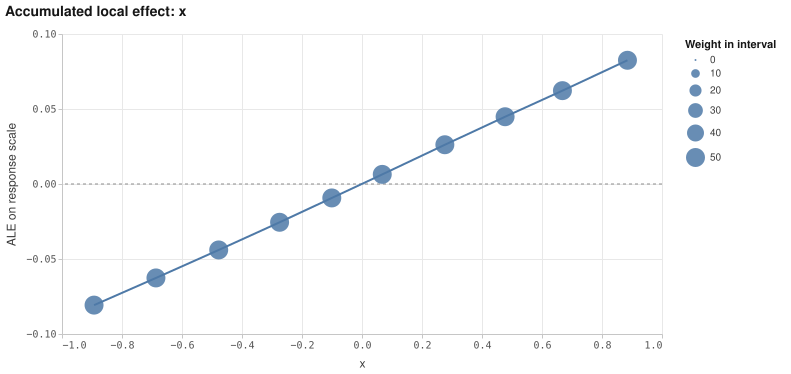

In [5]:
ale = mb.accumulated_local_effect(fit, data, "x", bins=10, type="response")
display(ale.to_frame(output="polars"))
mb.plot.plot_accumulated_local_effect(ale)


## Limitations

A contrast result attaches no sampling, learner-selection, or model-specification
uncertainty. Variation among `individual` values describes heterogeneity of fitted
prediction changes across the supplied rows; it is not a standard error. Clustered or
survey populations require a variance design for the weighted average. Correlated
predictors also make settings that hold every other column fixed sparse or impossible in
the observed joint support. Accumulated local effects reduce global extrapolation by
using resident rows, but multidimensional joint-support diagnostics remain separate.
